# 02. Huấn luyện Thực tế ResNet-18 From Scratch (20 Epochs) & Đánh giá Metrics
Notebook được xây dựng tường minh từng bước tham khảo chuẩn **ResNet18 from Scratch Using PyTorch (GeeksforGeeks)**, mở rộng sang bài toán **Multi-task (Giới tính [Chuỗi xác suất] + Tuổi [Regression])** trên tập dữ liệu Châu Á (`16.522` ảnh, `224×224`, `0=Female / 1=Male`).

**Hỗ trợ chạy cả 2 môi trường:**
- **Google Colab (CHỈ CẦN upload 1 file `dataset.zip` lên `MyDrive/dataset.zip`):** Cell 1 tự mount Drive, giải nén `MyDrive/dataset.zip` ra SSD `/content/` để train tốc độ cao, và tự sao lưu `checkpoints/` + `results/` về `MyDrive/resnet18_outputs/`.
- **Local:** Tự nhận diện thư mục gốc trên máy và đọc trực tiếp từ `dataset/`.

In [1]:
# [Cell 1] Thiết lập môi trường (Colab chỉ cần MyDrive/dataset.zip / Local), GPU & Seed
import os, sys, random, json, time, shutil
import numpy as np
import torch

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

IN_COLAB = "google.colab" in sys.modules
DRIVE_SAVE_DIR = None
IMG_ROOT_OVERRIDE = None

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

    DRIVE_DATASET_ZIP = "/content/drive/MyDrive/dataset.zip"
    DRIVE_PROJECT_DIR = "/content/drive/MyDrive/FINAL-PROJECT"
    DRIVE_SAVE_DIR = "/content/drive/MyDrive/resnet18_outputs"
    os.makedirs(DRIVE_SAVE_DIR, exist_ok=True)

    # Giải nén dataset.zip từ MyDrive sang SSD /content/ nếu chưa giải nén
    if os.path.exists(DRIVE_DATASET_ZIP):
        if not os.path.exists("/content/dataset/metadata/train.csv"):
            print(f"Đang giải nén {DRIVE_DATASET_ZIP} sang /content/ ...")
            !unzip -q "{DRIVE_DATASET_ZIP}" -d "/content"
        # Tự động xử lý nếu bên trong zip bị lồng thêm 1 cấp thư mục dataset/
        if os.path.exists("/content/dataset/dataset/metadata/train.csv"):
            os.chdir("/content/dataset")
        elif os.path.exists("/content/dataset/metadata/train.csv"):
            os.chdir("/content")
        else:
            raise FileNotFoundError("Không tìm thấy dataset/metadata/train.csv sau khi giải nén dataset.zip!")
    elif os.path.exists(DRIVE_PROJECT_DIR):
        os.chdir(DRIVE_PROJECT_DIR)
    else:
        raise FileNotFoundError(
            "Không tìm thấy /content/drive/MyDrive/dataset.zip! "
            "Hãy upload file dataset.zip lên thư mục ngoài cùng MyDrive."
        )
else:
    cur = os.path.abspath(os.getcwd())
    while not os.path.isdir(os.path.join(cur, "dataset", "metadata")) and cur != os.path.dirname(cur):
        cur = os.path.dirname(cur)
    os.chdir(cur)

if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Working directory:", os.getcwd())
print("train.csv exists:", os.path.exists("dataset/metadata/train.csv"))
print("processed exists:", os.path.isdir("dataset/processed"))
print("Device:", device, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Mounted at /content/drive
Đang giải nén /content/drive/MyDrive/dataset.zip sang /content/ ...
Working directory: /content
train.csv exists: True
processed exists: True
Device: cuda | GPU: Tesla T4


In [2]:
# [Cell 2] Đọc dữ liệu thật (train/val/test.csv), Data Augmentation (224x224) & DataLoader
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms

# Đọc Mean/Std đã tính trên tập Train
with open("dataset/metadata/norm_stats.json", "r", encoding="utf-8") as f:
    norm_stats = json.load(f)
TRAIN_MEAN, TRAIN_STD = norm_stats["mean"], norm_stats["std"]
print("Train Norm Stats (224x224):", TRAIN_MEAN, TRAIN_STD)

IMG_SIZE = 224
BATCH_SIZE = 64
NUM_WORKERS = 0  # Để 0 để tránh cảnh báo _MultiProcessingDataLoaderIter.__del__ trên Python 3.13 Colab
USE_BALANCED_SAMPLER = True  # Bật WeightedRandomSampler để cân bằng 9 nhóm tuổi x 2 giới tính khi train

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=TRAIN_MEAN, std=TRAIN_STD),
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=TRAIN_MEAN, std=TRAIN_STD),
])

class AsianFaceDataset(Dataset):
    def __init__(self, csv_path, transform=None, img_root_override=None):
        self.df = pd.read_csv(csv_path)
        if img_root_override:
            self.df["image_path"] = self.df["image_path"].astype(str).str.replace("dataset/processed", img_root_override, regex=False)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row["image_path"]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        gender = torch.tensor(int(row["gender"]), dtype=torch.long)  # 0=Female, 1=Male
        age = torch.tensor(float(row["age"]), dtype=torch.float32)
        return img, gender, age

train_ds = AsianFaceDataset("dataset/metadata/train.csv", transform=train_transform, img_root_override=IMG_ROOT_OVERRIDE)
val_ds = AsianFaceDataset("dataset/metadata/val.csv", transform=val_transform, img_root_override=IMG_ROOT_OVERRIDE)
test_ds = AsianFaceDataset("dataset/metadata/test.csv", transform=val_transform, img_root_override=IMG_ROOT_OVERRIDE)

if USE_BALANCED_SAMPLER:
    strat_key = train_ds.df["age_group"].astype(str) + "_" + train_ds.df["gender"].astype(str)
    counts = strat_key.value_counts().to_dict()
    sample_weights = strat_key.map(lambda k: 1.0 / counts[k]).values
    sampler = WeightedRandomSampler(weights=torch.DoubleTensor(sample_weights), num_samples=len(sample_weights), replacement=True)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=NUM_WORKERS, pin_memory=True)
else:
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)

val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

print(f"Dataset loaded -> Train: {len(train_ds):,} | Val: {len(val_ds):,} | Test: {len(test_ds):,}")

Train Norm Stats (224x224): [0.535029, 0.42123, 0.372826] [0.276233, 0.248417, 0.242609]
Dataset loaded -> Train: 11,565 | Val: 2,478 | Test: 2,479


In [3]:
# [Cell 3] Định nghĩa kiến trúc ResNet-18 From Scratch (theo chuẩn GeeksforGeeks) + Multi-task Heads
import torch.nn as nn

class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels * self.expansion:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels * self.expansion, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels * self.expansion),
            )

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        return self.relu(out)


class ResNet18MultiTask(nn.Module):
    def __init__(self, num_genders=2, dropout=0.3):
        super().__init__()
        self.in_channels = 64
        # Stem: Conv 7x7 stride 2 -> BN -> ReLU -> MaxPool 3x3 stride 2
        self.conv1 = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

        # 4 Stages: [2, 2, 2, 2]
        self.layer1 = self._make_layer(64, num_blocks=2, stride=1)
        self.layer2 = self._make_layer(128, num_blocks=2, stride=2)
        self.layer3 = self._make_layer(256, num_blocks=2, stride=2)
        self.layer4 = self._make_layer(512, num_blocks=2, stride=2)

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(dropout)
        self.gender_head = nn.Linear(512 * BasicBlock.expansion, num_genders)  # Logits -> Softmax chuỗi xác suất
        self.age_head = nn.Linear(512 * BasicBlock.expansion, 1)              # Age Regression
        self._init_weights()

    def _make_layer(self, out_channels, num_blocks, stride):
        strides = [stride] + [1] * (num_blocks - 1)
        layers = []
        for s in strides:
            layers.append(BasicBlock(self.in_channels, out_channels, stride=s))
            self.in_channels = out_channels * BasicBlock.expansion
        return nn.Sequential(*layers)

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def forward(self, x):
        x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        feats = self.dropout(self.avgpool(x).flatten(1))
        return self.gender_head(feats), self.age_head(feats).squeeze(1)

    @torch.no_grad()
    def predict_proba(self, x):
        g_logits, a_pred = self.forward(x)
        return torch.softmax(g_logits, dim=1), a_pred

model = ResNet18MultiTask(num_genders=2, dropout=0.3).to(device)
print(f"ResNet-18 Multi-task (from scratch) | Tổng tham số: {sum(p.numel() for p in model.parameters())/1e6:.2f}M")

# Kiểm tra trên 1 batch dữ liệu thật đầu tiên từ train_loader
real_imgs, real_genders, real_ages = next(iter(train_loader))
probs_chk, ages_chk = model.predict_proba(real_imgs[:4].to(device))
print("Real batch shape:", real_imgs.shape, "| Probs[0]:", probs_chk[0].cpu().tolist(), "| Age pred[0]:", round(ages_chk[0].item(), 2))

ResNet-18 Multi-task (from scratch) | Tổng tham số: 11.18M
Real batch shape: torch.Size([64, 3, 224, 224]) | Probs[0]: [0.4820728302001953, 0.5179271697998047] | Age pred[0]: -0.49


In [4]:
# [Cell 4] Khởi tạo Loss Function, Optimizer & Learning Rate Scheduler
NUM_EPOCHS = 20
LR = 1e-3
W_GENDER = 1.0
W_AGE = 0.1

gender_criterion = nn.CrossEntropyLoss()
age_criterion = nn.SmoothL1Loss()

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)
scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

In [5]:
# [Cell 5] Vòng lặp Huấn luyện Thật 20 Epochs & Lưu Checkpoint (best + epoch 20)
from tqdm.auto import tqdm

os.makedirs("checkpoints", exist_ok=True)
os.makedirs("results/resnet18", exist_ok=True)

history = []
best_val_loss = float("inf")
t_start = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    # --- TRAIN ---
    model.train()
    tr_loss_sum, tr_correct, tr_mae_sum, tr_n = 0.0, 0, 0.0, 0
    for imgs, genders, ages in tqdm(train_loader, desc=f"Epoch {epoch:02d}/{NUM_EPOCHS} [Train]", leave=False):
        imgs, genders, ages = imgs.to(device, non_blocking=True), genders.to(device, non_blocking=True), ages.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
            g_logits, a_pred = model(imgs)
            loss = W_GENDER * gender_criterion(g_logits, genders) + W_AGE * age_criterion(a_pred, ages)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        bs = imgs.size(0)
        tr_loss_sum += loss.item() * bs
        tr_correct += (g_logits.argmax(1) == genders).sum().item()
        tr_mae_sum += torch.abs(a_pred - ages).sum().item()
        tr_n += bs

    # --- VALIDATION ---
    model.eval()
    va_loss_sum, va_correct, va_mae_sum, va_n = 0.0, 0, 0.0, 0
    with torch.no_grad():
        for imgs, genders, ages in val_loader:
            imgs, genders, ages = imgs.to(device, non_blocking=True), genders.to(device, non_blocking=True), ages.to(device, non_blocking=True)
            g_logits, a_pred = model(imgs)
            loss = W_GENDER * gender_criterion(g_logits, genders) + W_AGE * age_criterion(a_pred, ages)

            bs = imgs.size(0)
            va_loss_sum += loss.item() * bs
            va_correct += (g_logits.argmax(1) == genders).sum().item()
            va_mae_sum += torch.abs(a_pred - ages).sum().item()
            va_n += bs

    scheduler.step()

    row = {
        "epoch": epoch,
        "tr_loss": tr_loss_sum / tr_n, "tr_acc": tr_correct / tr_n, "tr_mae": tr_mae_sum / tr_n,
        "val_loss": va_loss_sum / va_n, "val_acc": va_correct / va_n, "val_mae": va_mae_sum / va_n,
    }
    history.append(row)
    print(f"Epoch [{epoch:02d}/{NUM_EPOCHS}] | "
          f"Train Loss: {row['tr_loss']:.4f}, Acc: {row['tr_acc']*100:.2f}%, MAE: {row['tr_mae']:.2f} | "
          f"Val Loss: {row['val_loss']:.4f}, Acc: {row['val_acc']*100:.2f}%, MAE: {row['val_mae']:.2f}")

    if row["val_loss"] < best_val_loss:
        best_val_loss = row["val_loss"]
        torch.save({"epoch": epoch, "model_state_dict": model.state_dict(), "optimizer_state_dict": optimizer.state_dict(), "best_val_loss": best_val_loss},
                   "checkpoints/resnet18_best.pth")

torch.save({"epoch": NUM_EPOCHS, "model_state_dict": model.state_dict(), "optimizer_state_dict": optimizer.state_dict(), "best_val_loss": best_val_loss},
           f"checkpoints/resnet18_epoch_{NUM_EPOCHS}.pth")
pd.DataFrame(history).to_csv("results/resnet18/history.csv", index=False)
if DRIVE_SAVE_DIR:
    shutil.copytree("checkpoints", os.path.join(DRIVE_SAVE_DIR, "checkpoints"), dirs_exist_ok=True)
    shutil.copytree("results", os.path.join(DRIVE_SAVE_DIR, "results"), dirs_exist_ok=True)
    print("Đã đồng bộ checkpoints & results về Google Drive:", DRIVE_SAVE_DIR)
print(f"Hoàn tất 20 epochs trong {(time.time()-t_start)/60:.1f} phút! Đã lưu checkpoints & history.csv.")

Epoch 01/20 [Train]:   0%|          | 0/181 [00:00<?, ?it/s]

Epoch [01/20] | Train Loss: 2.8507, Acc: 55.26%, MAE: 21.65 | Val Loss: 2.2937, Acc: 52.87%, MAE: 16.50


Epoch 02/20 [Train]:   0%|          | 0/181 [00:00<?, ?it/s]

Epoch [02/20] | Train Loss: 2.1909, Acc: 60.61%, MAE: 15.83 | Val Loss: 2.1158, Acc: 62.71%, MAE: 14.63


Epoch 03/20 [Train]:   0%|          | 0/181 [00:00<?, ?it/s]

Epoch [03/20] | Train Loss: 1.8270, Acc: 66.38%, MAE: 12.73 | Val Loss: 1.6425, Acc: 67.47%, MAE: 10.91


... (30 outputs left out)

Epoch 19/20 [Train]:   0%|          | 0/181 [00:00<?, ?it/s]

Epoch [19/20] | Train Loss: 0.7338, Acc: 89.87%, MAE: 5.53 | Val Loss: 0.9170, Acc: 86.56%, MAE: 6.43


Epoch 20/20 [Train]:   0%|          | 0/181 [00:00<?, ?it/s]

Epoch [20/20] | Train Loss: 0.7290, Acc: 90.55%, MAE: 5.60 | Val Loss: 0.9099, Acc: 86.56%, MAE: 6.38
Đã đồng bộ checkpoints & results về Google Drive: /content/drive/MyDrive/resnet18_outputs
Hoàn tất 20 epochs trong 28.0 phút! Đã lưu checkpoints & history.csv.


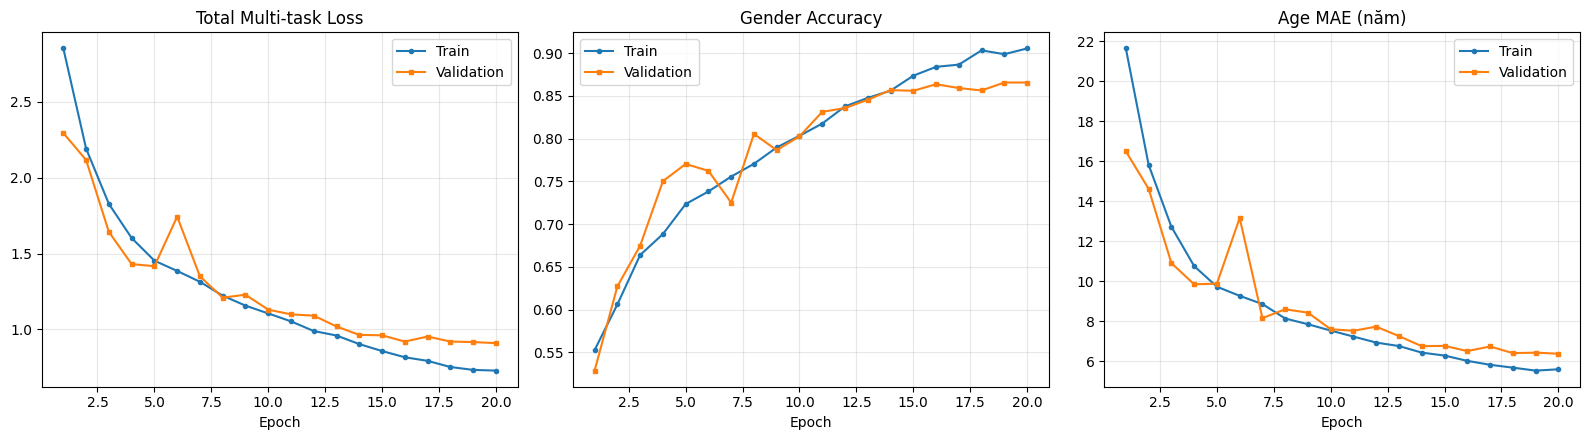

In [6]:
# [Cell 6] Vẽ biểu đồ Training & Validation Curves qua 20 Epochs
import matplotlib.pyplot as plt

hist_df = pd.read_csv("results/resnet18/history.csv")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, cols, title in zip(
    axes,
    [("tr_loss", "val_loss"), ("tr_acc", "val_acc"), ("tr_mae", "val_mae")],
    ["Total Multi-task Loss", "Gender Accuracy", "Age MAE (năm)"],
):
    ax.plot(hist_df["epoch"], hist_df[cols[0]], marker="o", markersize=3, label="Train")
    ax.plot(hist_df["epoch"], hist_df[cols[1]], marker="s", markersize=3, label="Validation")
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.grid(alpha=0.3); ax.legend()

plt.tight_layout()
plt.savefig("results/resnet18/training_curves.png", dpi=150)
plt.show()

,model,gender_acc,gender_f1_macro,gender_roc_auc,age_mae_all,age_mae_exact_sources,age_rmse,age_cs_5 (%),inference_ms_per_img,params_M
0,resnet18,0.864461,0.86444,0.943793,6.516987,6.130023,9.538058,55.344897,4.128,11.18


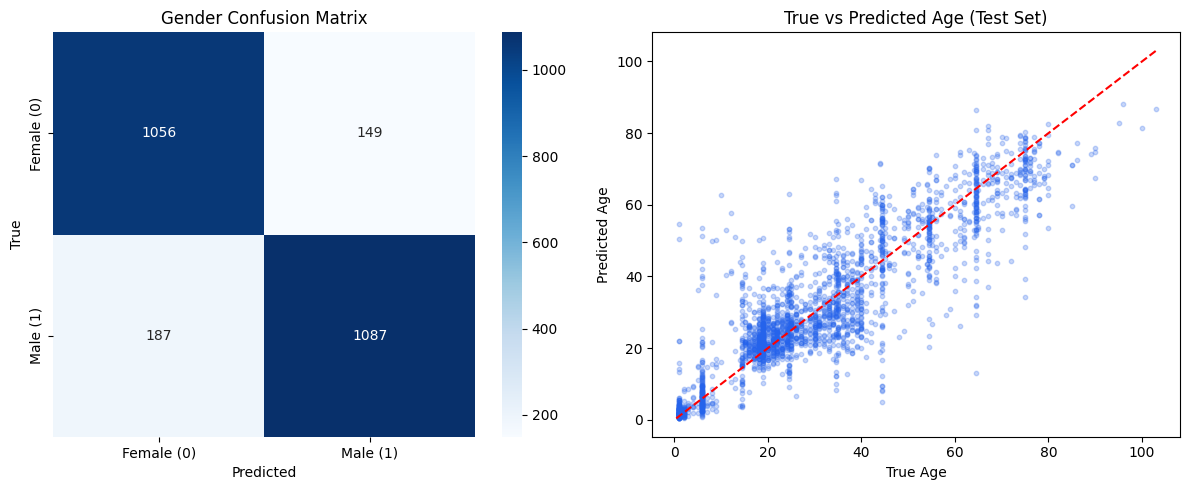

Đã cập nhật kết quả đánh giá lên Google Drive: /content/drive/MyDrive/resnet18_outputs


In [7]:
# [Cell 7] Đánh giá toàn diện trên tập Test (Accuracy, Macro F1, ROC-AUC, MAE, RMSE, CS(5))
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, mean_absolute_error, mean_squared_error, roc_auc_score

ckpt = torch.load("checkpoints/resnet18_best.pth", map_location=device)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

all_probs, all_g_true, all_a_pred, all_a_true = [], [], [], []
t0 = time.time()
with torch.no_grad():
    for imgs, genders, ages in test_loader:
        probs, a_pred = model.predict_proba(imgs.to(device))
        all_probs.append(probs.cpu().numpy())
        all_g_true.append(genders.numpy())
        all_a_pred.append(a_pred.cpu().numpy())
        all_a_true.append(ages.numpy())
infer_ms = (time.time() - t0) * 1000.0 / len(test_ds)

gender_probs = np.concatenate(all_probs)
gender_true = np.concatenate(all_g_true)
gender_pred = np.argmax(gender_probs, axis=1)
age_pred = np.concatenate(all_a_pred)
age_true = np.concatenate(all_a_true)

# Tính metrics tổng thể và MAE riêng cho nhóm tuổi thật (không gồm FairFace midpoint)
test_meta = test_ds.df.copy()
exact_mask = test_meta["source"] != "FairFace"

metrics = {
    "model": "resnet18",
    "gender_acc": float(accuracy_score(gender_true, gender_pred)),
    "gender_f1_macro": float(f1_score(gender_true, gender_pred, average="macro")),
    "gender_roc_auc": float(roc_auc_score(gender_true, gender_probs[:, 1])),
    "age_mae_all": float(mean_absolute_error(age_true, age_pred)),
    "age_mae_exact_sources": float(mean_absolute_error(age_true[exact_mask], age_pred[exact_mask])),
    "age_rmse": float(np.sqrt(mean_squared_error(age_true, age_pred))),
    "age_cs_5 (%)": float(np.mean(np.abs(age_pred - age_true) <= 5.0) * 100.0),
    "inference_ms_per_img": round(infer_ms, 3),
    "params_M": round(sum(p.numel() for p in model.parameters()) / 1e6, 2),
}
with open("results/resnet18/test_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)
display(pd.DataFrame([metrics]))

# Vẽ Confusion Matrix & Age Scatter Plot
cm = confusion_matrix(gender_true, gender_pred)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Female (0)", "Male (1)"], yticklabels=["Female (0)", "Male (1)"], ax=axes[0])
axes[0].set_title("Gender Confusion Matrix"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True")

axes[1].scatter(age_true, age_pred, alpha=0.25, s=10, color="#2563eb")
lims = [min(age_true.min(), age_pred.min()), max(age_true.max(), age_pred.max())]
axes[1].plot(lims, lims, "r--")
axes[1].set_title("True vs Predicted Age (Test Set)"); axes[1].set_xlabel("True Age"); axes[1].set_ylabel("Predicted Age")
plt.tight_layout(); plt.savefig("results/resnet18/test_evaluation_plots.png", dpi=150); plt.show()
if DRIVE_SAVE_DIR:
    shutil.copytree("results", os.path.join(DRIVE_SAVE_DIR, "results"), dirs_exist_ok=True)
    print("Đã cập nhật kết quả đánh giá lên Google Drive:", DRIVE_SAVE_DIR)

=== MAE THEO 9 NHÓM TUỔI ===


,count,mean
age_group,,
0-2,212,2.12
10-19,464,6.21
20-29,483,5.05
3-9,201,5.15
30-39,414,7.55
40-49,215,10.11
50-59,156,7.63
60-69,183,8.24
70+,151,8.96



=== TOP 8 ẢNH ĐOÁN TUỔI LỆCH NHIỀU NHẤT ===


,source,age_group,age,pred_age,age_error,p_female,p_male
1985,FairFace,0-2,1.0,54.599998,53.560001,0.4462,0.5538
1033,AAF,10-19,10.0,62.700001,52.700001,0.9816,0.0184
1624,FairFace,60-69,64.5,13.100000,51.400002,0.8251,0.1749
1515,FairFace,0-2,1.0,50.500000,49.459999,0.9778,0.0222
2146,FairFace,3-9,6.0,53.500000,47.529999,0.7852,0.2148
2443,AAF,10-19,12.0,57.700001,45.700001,0.9007,0.0993
2233,FairFace,3-9,6.0,51.400002,45.369999,0.0809,0.9191
516,AAF,10-19,11.0,53.000000,42.040001,0.8846,0.1154


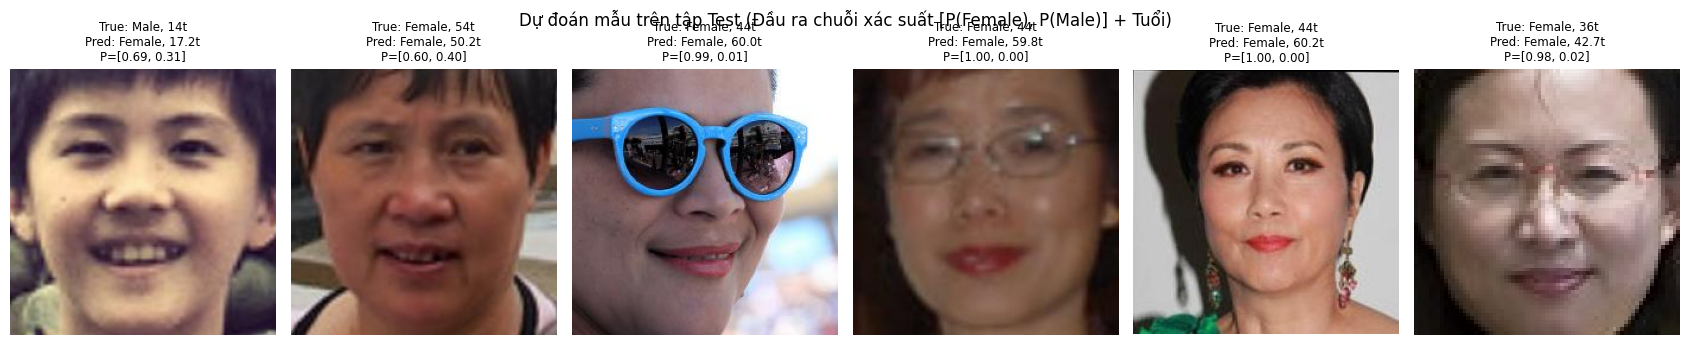

In [8]:
# [Cell 8] Phân tích lỗi (Error Analysis) & In chuỗi xác suất dự đoán trên ảnh Test mẫu
test_meta["p_female"] = np.round(gender_probs[:, 0], 4)
test_meta["p_male"] = np.round(gender_probs[:, 1], 4)
test_meta["pred_gender"] = gender_pred
test_meta["pred_age"] = np.round(age_pred, 1)
test_meta["age_error"] = np.round(np.abs(age_pred - age_true), 2)

print("=== MAE THEO 9 NHÓM TUỔI ===")
display(test_meta.groupby("age_group")["age_error"].agg(["count", "mean"]).round(2))

print("\n=== TOP 8 ẢNH ĐOÁN TUỔI LỆCH NHIỀU NHẤT ===")
display(test_meta.sort_values("age_error", ascending=False)[["source", "age_group", "age", "pred_age", "age_error", "p_female", "p_male"]].head(8))

# Hiển thị 6 ảnh Test ngẫu nhiên kèm CHUỖI XÁC SUẤT [P(Female), P(Male)] & tuổi dự đoán
sample_rows = test_meta.sample(6, random_state=42)
fig, axes = plt.subplots(1, 6, figsize=(17, 3.6))
for ax, row in zip(axes, sample_rows.itertuples()):
    with Image.open(row.image_path) as im:
        ax.imshow(im.convert("RGB"))
    g_true = "Female" if row.gender == 0 else "Male"
    g_pred = "Female" if row.pred_gender == 0 else "Male"
    ax.set_title(f"True: {g_true}, {row.age:.0f}t\nPred: {g_pred}, {row.pred_age:.1f}t\nP=[{row.p_female:.2f}, {row.p_male:.2f}]", fontsize=8.5)
    ax.axis("off")
plt.suptitle("Dự đoán mẫu trên tập Test (Đầu ra chuỗi xác suất [P(Female), P(Male)] + Tuổi)", fontsize=12)
plt.tight_layout(); plt.show()